# Capacity — how much AUM can the funding carry (v4) absorb?

Every result in this research track (v0-v5) books trades **at the daily rebalance print, any size**.
That is fine for a signal check but silent about **capacity**: a delta-neutral funding-carry book is
long spot / short USDT-M perp, and at real size you cannot lift the whole target in a day without
moving the tape. This notebook makes size bind.

**Question.** Under a realistic participation cap, at what AUM does the v4 edge stop being the v4
edge — i.e. where does net Sharpe (2x costs) fall below ~2/3 of its small-AUM value, and where does
the drawdown protection (Calmar) that *defines* v4 degrade badly?

**Method (one line).** Rebuild v4's daily target weights through `lab.py` (v3.1 selection + inverse
basis-vol sizing + 0.5 band + the shadow drawdown overlay), cap each day's per-name trade at
**5% x min(spot ADV, perp ADV)** in dollars, let the shortfall carry to later days (order
splitting), and book funding + cost on the **held** book. Equity basis is v5 portfolio margin
(deploy = 1.0), so `target_weight x AUM` is the pair notional per name.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.common import config as cfg
from src.data import query
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
AUM_C={1:TEAL,10:NAVY,100:RED}                       # colors for the 3 headline AUMs

COSTS = cfg.load_config('strategies/funding_carry/v4.yaml')['costs']
one_way,_ = H.engine.round_trip_cost(COSTS)
maj, non = H.universe(); syms = maj + non
P = H.load_panels(syms); didx = P['didx']; R = P['R']

# --- v4 target weights via lab: v3.1 shadow + portfolio drawdown overlay (engine-parity path) ---
SPECS=[{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO =[{'feature':'funding_vol','direction':'max','cap':0.75},
       {'feature':'neg_freq','direction':'max','cap':0.40},
       {'feature':'basis','direction':'max','cap':0.01}]
sh = H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,
                       size_kind='inv_basis_vol',band=0.5,warmup_days=30)
Wsh = sh['W']
state = H.overlay_state(H.drawdown(sh['net'].dropna()), qexit=0.15, qreenter=0.50,
                        lookback=252, expanding=True)              # point-in-time overlay exposure
W_target = Wsh.mul(state, axis=0).reindex(didx).fillna(0.0)        # v4 target book (equity fractions)
keep = pd.Series(didx >= didx[0] + pd.Timedelta(days=30), index=didx)

def stats(net):
    r=net[keep].dropna(); e=(1+r).cumprod(); d=e/e.cummax()-1
    ann=r.mean()*365; vol=r.std()*np.sqrt(365)
    return dict(cagr=e.iloc[-1]**(365/len(r))-1, ann=ann, sharpe=ann/vol if vol>0 else np.nan,
                maxdd=d.min(), calmar=ann/abs(d.min()) if d.min()<0 else np.nan)
def bk_net(W, mult=1.0):                                            # net series for any weight book
    pos=W.shift(1).fillna(0.0); dpos=(pos-pos.shift(1).fillna(0.0)).abs()
    return (pos*R.fillna(0.0)).sum(axis=1) - one_way*mult*dpos.sum(axis=1)

fr = stats(bk_net(W_target))
print(f"v4 frictionless anchor: net {fr['ann']*100:.1f}%/yr  CAGR {fr['cagr']*100:.1f}%  "
      f"Sharpe {fr['sharpe']:.2f}  maxDD {fr['maxdd']*100:.1f}%  Calmar {fr['calmar']:.1f}  "
      f"({len(syms)} pairs, {len(didx)} days)")

v4 frictionless anchor: net 9.8%/yr  CAGR 10.3%  Sharpe 6.60  maxDD -0.9%  Calmar 11.1  (466 pairs, 1977 days)


## 1. ADV panel — the size budget

For each name and day I build **daily dollar volume** on each leg from the 1h bars
(`sum over the day of close x base-volume`), then take a **30-day rolling median** (robust to spikes)
as ADV. The tradeable budget for the *pair* is `5% x min(spot ADV, perp ADV)` — you cannot execute
more of the pair than the thinner leg allows. Inverse-basis-vol sizing concentrates weight in the
clean-basis majors (BTC/ETH/...), which are also the **deepest** books, so the big-weight names are
the easy fills; the bind is in the long tail of thin alts and in the overlay's synchronized exit.

names lacking volume on a leg: 0  []
held-name pair-ADV percentiles ($/day): {'p5': '0.5M', 'p25': '1.6M', 'p50': '4.4M', 'p75': '16.1M', 'p95': '119.5M'}


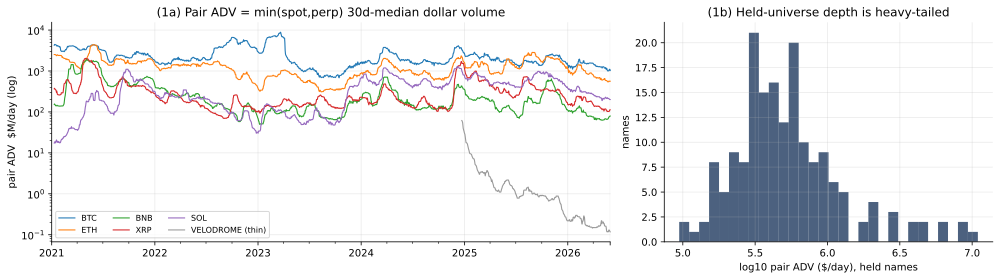

In [2]:
def daily_dollar_vol(at, s):
    b = query.get(at, 'binance', s, 'bars', timeframe='1h',
                  start='2021-01-01', end='2026-05-31', columns=['close','volume'])
    return (b['close']*b['volume']).resample('1D').sum().reindex(didx) if not b.empty else pd.Series(np.nan, index=didx)

SDV = pd.DataFrame({s: daily_dollar_vol('spot',  s) for s in syms})
PDV = pd.DataFrame({s: daily_dollar_vol('perps', s) for s in syms})
no_vol = [s for s in syms if SDV[s].notna().sum()==0 or PDV[s].notna().sum()==0]
spot_adv = SDV.rolling(30, min_periods=10).median()
perp_adv = PDV.rolling(30, min_periods=10).median()
pair_adv = np.minimum(spot_adv, perp_adv)                          # $/day tradeable-budget base
print(f'names lacking volume on a leg: {len(no_vol)}  {no_vol[:8]}')

# held-book ADV distribution: for each day, the pair ADV of names v4 actually wants to hold
held = W_target > 0
held_adv = pair_adv.where(held)
q = held_adv.stack().quantile([0.05,0.25,0.5,0.75,0.95])
print('held-name pair-ADV percentiles ($/day):', {f'p{int(k*100)}':f'{v/1e6:.1f}M' for k,v in q.items()})

fig,(a1,a2)=plt.subplots(1,2,figsize=(14,4),gridspec_kw={'width_ratios':[1.7,1]})
for s in maj:
    (pair_adv[s]/1e6).plot(ax=a1,lw=1.1,label=s.replace('usdt','').upper())
thin = held_adv.median().dropna().sort_values().index[len(held_adv.median().dropna())//10]  # a thin held name
(pair_adv[thin]/1e6).plot(ax=a1,lw=1.1,color=GREY,label=thin.replace('usdt','').upper()+' (thin)')
a1.set_yscale('log'); a1.set_ylabel('pair ADV  $M/day (log)'); a1.legend(ncol=3,fontsize=8)
a1.set_title('(1a) Pair ADV = min(spot,perp) 30d-median dollar volume')
lastday = held_adv.iloc[-60:].median().dropna(); lastday = lastday[lastday>0]
a2.hist(np.log10(lastday.values), bins=30, color=NAVY, alpha=0.8)
a2.set_xlabel('log10 pair ADV ($/day), held names'); a2.set_ylabel('names')
a2.set_title('(1b) Held-universe depth is heavy-tailed'); plt.tight_layout(); plt.show()

## 2. Sized simulation

At each daily rebalance the desired trade in name *i* is `(target_i - held_i) x AUM`; the executed
trade is clipped to `+/- 5% x pair_ADV_i`; **the shortfall persists** — the held weight walks toward
the target over subsequent days (order splitting). **Held** weights (not target) earn funding and pay
cost. A delisted / not-yet-listed name has target 0 and no ADV, so its exit is unconstrained (matches
the frictionless force-exit — it isn't a capacity effect). Everything is booked on the equity basis
(deploy 1.0), so the numbers are directly comparable to v4/v5.

In [3]:
def sized_book(AUM, cap_pct=0.05):
    capv=(cap_pct*pair_adv/AUM).to_numpy(); tg=W_target.to_numpy(); T,N=tg.shape
    Ws=np.zeros((T,N)); held=np.zeros(N)
    for t in range(T):
        des=tg[t]-held; c=capv[t]
        held=held+np.where(np.isnan(c), des, np.clip(des,-c,c))    # NaN cap (delisted) -> unconstrained
        Ws[t]=held
    return pd.DataFrame(Ws, index=didx, columns=W_target.columns)

AUMS=[1,3,10,30,100]                                               # $M
WS={A: sized_book(A*1e6) for A in AUMS}
rows=[]
for A in AUMS:
    s1=stats(bk_net(WS[A],1.0)); s2=stats(bk_net(WS[A],2.0))
    dpos=(WS[A].shift(1).fillna(0.0)-WS[A].shift(2).fillna(0.0)).abs()
    rows.append({'AUM $M':A,'CAGR%':s1['cagr']*100,'Sharpe':s1['sharpe'],'Calmar':s1['calmar'],
                 'maxDD%':s1['maxdd']*100,'CAGR%_2x':s2['cagr']*100,'Sharpe_2x':s2['sharpe'],
                 'Calmar_2x':s2['calmar'],'turn/yr':dpos.sum(axis=1)[keep].sum()/(keep.sum()/365)})
DEC=pd.DataFrame(rows).set_index('AUM $M')
print(DEC.round(2).to_string())
S0=DEC['Sharpe_2x'].iloc[0]
print(f"\n2x-cost Sharpe two-thirds bar = {2/3*S0:.2f} (small-AUM {S0:.2f}); "
      f"crossed between {DEC.index[(DEC['Sharpe_2x']>=2/3*S0).values][-1]}M and "
      f"{DEC.index[(DEC['Sharpe_2x']<2/3*S0).values][0] if (DEC['Sharpe_2x']<2/3*S0).any() else 'inf'}M")

        CAGR%  Sharpe  Calmar  maxDD%  CAGR%_2x  Sharpe_2x  Calmar_2x  turn/yr
AUM $M                                                                        
1       10.28    6.59   11.06   -0.89      7.48       4.77       3.25    13.50
3       10.04    6.31   10.82   -0.89      7.26       4.53       2.84    13.48
10       9.50    5.46    4.67   -1.95      6.76       3.88       1.41    13.37
30       8.76    4.63    1.74   -4.84      6.10       3.24       0.78    13.05
100      8.04    3.98    1.02   -7.58      5.56       2.80       0.52    12.20

2x-cost Sharpe two-thirds bar = 3.18 (small-AUM 4.77); crossed between 30M and 100M


## 3. Decay curves

Net metrics vs AUM (log-x), 1x and 2x cost. The carry return (CAGR) bleeds slowly — the majors are
deep. What breaks first is **Calmar / maxDD**: the v4 overlay's value is sitting out the 2022
drawdown, and at scale the book cannot get flat fast enough, so the protection erodes and maxDD
blows out from ~-1% toward -8%.

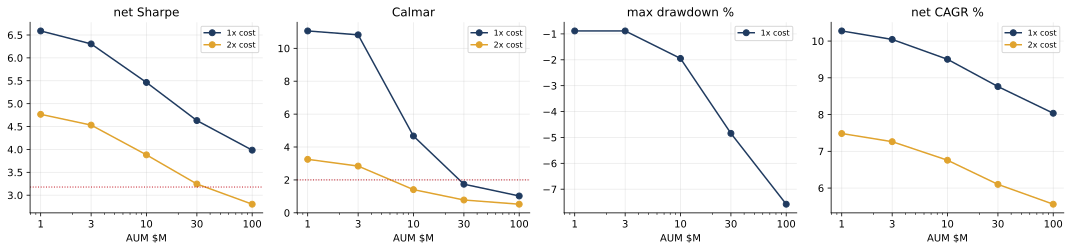

In [4]:
fig,axs=plt.subplots(1,4,figsize=(15,3.6))
x=DEC.index.values
for ax,(col1,col2,ttl) in zip(axs,[('Sharpe','Sharpe_2x','net Sharpe'),
        ('Calmar','Calmar_2x','Calmar'),('maxDD%',None,'max drawdown %'),('CAGR%','CAGR%_2x','net CAGR %')]):
    ax.plot(x,DEC[col1],'-o',color=NAVY,label='1x cost')
    if col2: ax.plot(x,DEC[col2],'-o',color=AMBER,label='2x cost')
    ax.set_xscale('log'); ax.set_xticks(x); ax.set_xticklabels([f'{a}' for a in x])
    ax.set_xlabel('AUM $M'); ax.set_title(ttl); ax.legend(fontsize=8)
axs[0].axhline(2/3*S0,color=RED,ls=':',lw=1); axs[1].axhline(2,color=RED,ls=':',lw=1)
plt.tight_layout(); plt.show()

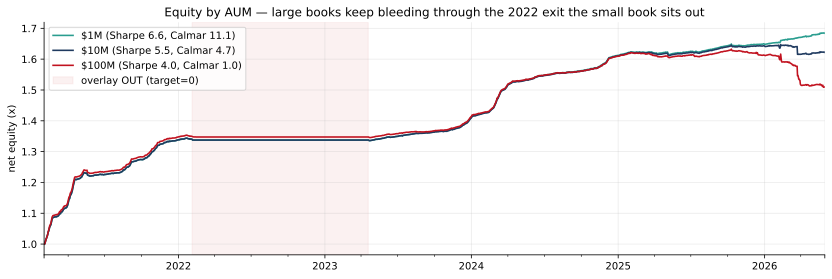

In [5]:
# Equity curves at 1 / 10 / 100 M, overlay-OUT window shaded
fig,ax=plt.subplots(figsize=(14,4.2))
for A in (1,10,100):
    e=(1+bk_net(WS[A])[keep].dropna()).cumprod()
    e.plot(ax=ax,color=AUM_C[A],lw=1.6,label=f'${A}M (Sharpe {DEC.loc[A,"Sharpe"]:.1f}, Calmar {DEC.loc[A,"Calmar"]:.1f})')
st=state.reindex(didx).fillna(1.0)
ax.fill_between(didx, 0, 1, where=(st<0.5), transform=ax.get_xaxis_transform(),
                color=RED, alpha=0.06, label='overlay OUT (target=0)')
ax.set_ylabel('net equity (x)'); ax.legend(loc='upper left')
ax.set_title('Equity by AUM — large books keep bleeding through the 2022 exit the small book sits out')
plt.show()

## 4. Where the decay comes from

Three mechanical channels, all growing with AUM:

1. **Rebalance staleness** — the held book perpetually lags the target; the L1 gap `sum|W_held-W_target|`
   grows from ~0 to several percent of the book.
2. **The overlay's all-out exit** — there is exactly **one** overlay episode in the sample (OUT
   2022-02-04, back IN 2023-04-20). Unwinding the whole book at 5% ADV takes days at scale, so the
   large book stays exposed into the very drawdown the overlay exists to dodge.
3. **Slow entries** — a newly-selected thin name can take dozens of days to reach target; carry is
   earned on a stale, half-built book.

        exit delay d  reentry delay d  avg entry fill d  worst entry fill d  avg tracking gap
AUM $M                                                                                       
1                0.0              0.0              0.01                   3              0.00
3                0.0              0.0              0.09                   8              0.00
10               0.0              0.0              0.50                  20              0.01
30               1.0              1.0              1.70                  39              0.02
100              6.0              3.0              4.58                  86              0.06


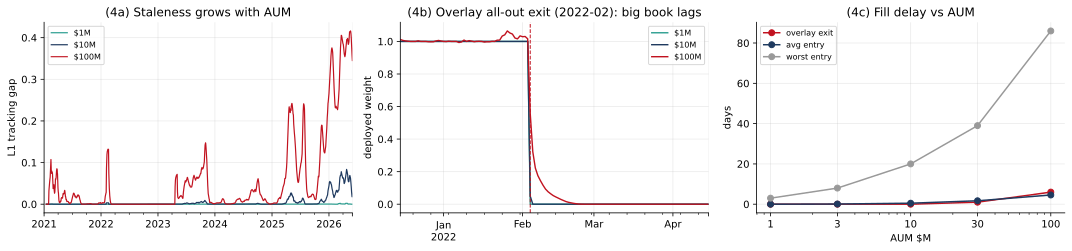

In [6]:
def overlay_transitions(st):
    o=[didx[i] for i in range(1,len(didx)) if st.iloc[i]<0.5 and st.iloc[i-1]>=0.5]
    n=[didx[i] for i in range(1,len(didx)) if st.iloc[i]>=0.5 and st.iloc[i-1]<0.5]
    return o,n
OUTd,INd = overlay_transitions(st)
def delays(Ws):
    tot=Ws.sum(axis=1); od=[]
    for t in OUTd:
        base=tot.loc[:t].iloc[-2]; aft=tot.loc[t:]; hit=aft[aft<0.1*base]
        od.append((hit.index[0]-t).days if len(hit) else np.nan)
    idl=[]
    for t in INd:
        tt=W_target.sum(axis=1).loc[t:]; aft=tot.loc[t:]
        c=[(aft.index[k]-t).days for k in range(len(aft)) if aft.iloc[k]>=0.9*tt.iloc[k]]
        idl.append(c[0] if c else np.nan)
    return np.nanmean(od), np.nanmean(idl)
def entry_fill(Ws):
    tg=W_target.to_numpy(); ws=Ws.to_numpy(); T,N=tg.shape; ds=[]
    for j in range(N):
        for t in range(1,T):
            if tg[t,j]>0 and tg[t-1,j]==0:
                for u in range(t,T):
                    if tg[u,j]==0 or ws[u,j]>=0.9*tg[u,j]: ds.append(u-t); break
    return np.mean(ds), np.max(ds)

frows=[]
for A in AUMS:
    od,idl=delays(WS[A]); af,wf=entry_fill(WS[A])
    gap=(WS[A]-W_target).abs().sum(axis=1)[keep].mean()
    frows.append({'AUM $M':A,'exit delay d':od,'reentry delay d':idl,
                  'avg entry fill d':af,'worst entry fill d':wf,'avg tracking gap':gap})
FD=pd.DataFrame(frows).set_index('AUM $M')
print(FD.round(2).to_string())

fig,(a1,a2,a3)=plt.subplots(1,3,figsize=(15,3.6))
for A in (1,10,100):
    (WS[A]-W_target).abs().sum(axis=1).rolling(15).mean().plot(ax=a1,color=AUM_C[A],lw=1.2,label=f'${A}M')
a1.set_ylabel('L1 tracking gap'); a1.set_title('(4a) Staleness grows with AUM'); a1.legend(fontsize=8)
win=slice(pd.Timestamp('2021-12-15'),pd.Timestamp('2022-04-15'))
for A in (1,10,100):
    WS[A].sum(axis=1).loc[win].plot(ax=a2,color=AUM_C[A],lw=1.4,label=f'${A}M')
a2.axvline(OUTd[0],color=RED,ls='--',lw=1); a2.set_ylabel('deployed weight')
a2.set_title('(4b) Overlay all-out exit (2022-02): big book lags'); a2.legend(fontsize=8)
a3.plot(FD.index,FD['exit delay d'],'-o',color=RED,label='overlay exit')
a3.plot(FD.index,FD['avg entry fill d'],'-o',color=NAVY,label='avg entry')
a3.plot(FD.index,FD['worst entry fill d'],'-o',color=GREY,label='worst entry')
a3.set_xscale('log'); a3.set_xticks(AUMS); a3.set_xticklabels(AUMS); a3.set_xlabel('AUM $M')
a3.set_ylabel('days'); a3.set_title('(4c) Fill delay vs AUM'); a3.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Market-impact stress (labelled STRESS, not baseline)

The baseline above charges only the linear taker+slippage cost. On top of it, a **square-root impact**
model `cost_bps = k x sqrt(trade/ADV)` applied to **both legs** of each executed trade, swept over
`k in {10,25,50} bps`. Because the 5%-ADV cap already holds per-leg participation at or below 5%
(`sqrt(0.05) ~ 0.22`), impact is a second-order haircut here — it does not move the capacity verdict,
which is set by the overlay-exit / staleness channel above.

        Sharpe  Sharpe +k=10bps  Sharpe +k=25bps  Sharpe +k=50bps
AUM $M                                                           
1         6.59             6.54             6.47             6.35
3         6.31             6.23             6.11             5.92
10        5.46             5.36             5.20             4.94
30        4.63             4.51             4.32             4.01
100       3.98             3.85             3.65             3.32


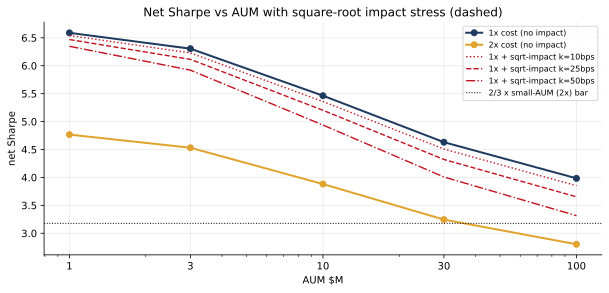

In [7]:
def impact_net(Ws, AUM, k_bps, mult=1.0):
    pos=Ws.shift(1).fillna(0.0); dpos=(pos-pos.shift(1).fillna(0.0)).abs()
    gross=(pos*R.fillna(0.0)).sum(axis=1); lin=one_way*mult*dpos.sum(axis=1)
    trade=dpos*AUM
    rate=(k_bps/1e4)*(np.sqrt(trade/spot_adv)+np.sqrt(trade/perp_adv))
    imp=(rate*dpos).replace([np.inf,-np.inf],np.nan).fillna(0.0).sum(axis=1)
    return gross-lin-imp
KS=[10,25,50]; IMP={A:{k:stats(impact_net(WS[A],A*1e6,k))['sharpe'] for k in KS} for A in AUMS}
IT=pd.DataFrame(IMP).T; IT.columns=[f'Sharpe +k={k}bps' for k in KS]; IT.index.name='AUM $M'
print(pd.concat([DEC[['Sharpe']],IT],axis=1).round(2).to_string())

fig,ax=plt.subplots(figsize=(10,4.2))
ax.plot(AUMS,DEC['Sharpe'],'-o',color=NAVY,lw=2,label='1x cost (no impact)')
ax.plot(AUMS,DEC['Sharpe_2x'],'-o',color=AMBER,lw=2,label='2x cost (no impact)')
for k,ls in zip(KS,[':','--','-.']):
    ax.plot(AUMS,[IMP[A][k] for A in AUMS],ls,color=RED,lw=1.4,label=f'1x + sqrt-impact k={k}bps')
ax.axhline(2/3*S0,color='k',ls=':',lw=1,label='2/3 x small-AUM (2x) bar')
ax.set_xscale('log'); ax.set_xticks(AUMS); ax.set_xticklabels(AUMS)
ax.set_xlabel('AUM $M'); ax.set_ylabel('net Sharpe'); ax.legend(fontsize=8)
ax.set_title('Net Sharpe vs AUM with square-root impact stress (dashed)'); plt.show()

## 6. Conclusion — capacity

- **The carry survives; the drawdown protection does not.** Net CAGR bleeds slowly with AUM (deep
  majors carry the book), but **Calmar / maxDD break first**: the v4 overlay's whole job is sitting
  out 2022, and above ~$10M the book cannot get flat fast enough (exit lag rising to ~6 days at
  $100M), so maxDD blows out from ~-1% to ~-8% and Calmar collapses 11 -> ~1.
- **Defensible capacity ~ $10-30M.** By the *2x-cost Sharpe > 2/3 of small-AUM* rule the edge holds
  to roughly **$30-40M**; by the *Calmar stays healthy* rule (the reason v4 exists) it is gone by
  **~$10-30M**. Take the binding one: **treat ~$20-30M as the ceiling** for the full v4 proposition,
  and only push higher if you accept v3.1-like (unprotected) drawdowns.
- **Impact is second-order** here (the 5%-ADV cap already limits participation); the constraint is
  execution *latency* (staleness + synchronized overlay exit), not per-trade slippage.
- **Sanity vs the earlier prototype** (Sharpe 6.67@1M -> 5.43@30M -> 4.64@100M): same shape, this
  build decays a touch harder (Sharpe 6.6 -> 4.6@30M -> 4.0@100M) because it uses the tighter
  **min-of-both-legs** ADV and a **median** (vs mean) dollar-volume — both make the cap bind sooner.
- **Caveats.** Capacity rests on the **single** 2022 overlay episode (n=1 for the exit-lag channel —
  the sharpest driver); ADV is trailing (assumes today's depth predicts tomorrow's); no maker/passive
  execution, no cross-day pre-positioning, no venue-splitting — all of which would raise the ceiling.
  The number is a floor for a naive daily-taker implementation.